Testing to see if a stock is a random walk

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf


In [4]:
msft = yf.Ticker("MSFT")
df = msft.history(period="1y")
print(df.head())

                                 Open        High         Low       Close  \
Date                                                                        
2025-10-17 00:00:00-04:00  504.885987  511.273405  503.170094  509.388947   
2025-10-20 00:00:00-04:00  510.410490  514.467140  509.240127  512.572693   
2025-10-21 00:00:00-04:00  513.276940  514.457232  508.853314  513.435608   
2025-10-22 00:00:00-04:00  516.897182  520.943844  513.485252  516.292114   
2025-10-23 00:00:00-04:00  518.196409  519.674240  514.377791  516.311890   

                             Volume  Dividends  Stock Splits  
Date                                                          
2025-10-17 00:00:00-04:00  19867800        0.0           0.0  
2025-10-20 00:00:00-04:00  14665600        0.0           0.0  
2025-10-21 00:00:00-04:00  15586200        0.0           0.0  
2025-10-22 00:00:00-04:00  18962700        0.0           0.0  
2025-10-23 00:00:00-04:00  14023500        0.0           0.0  


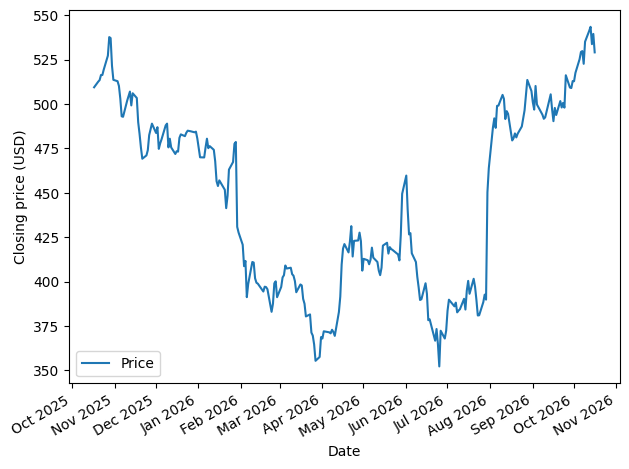

In [74]:
import matplotlib.dates as mdates
fig,ax = plt.subplots()

ax.plot(df.index, df['Close'], label="Price")
ax.set_xlabel("Date")
ax.set_ylabel("Closing price (USD)")
ax.legend(loc=3)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()

In [9]:
from statsmodels.tsa.stattools import adfuller
ADF_result = adfuller(df['Close'])

print(f"ADF Statistic: {ADF_result[0]}")
print(f"p-value: {ADF_result[1]}")

ADF Statistic: -1.3723654959423368
p-value: 0.5954504258796506


The ADF statistic is a large negative number but the p-value is not less than 0.05 so therefore the data is not stationary.

In [11]:
diff_close = np.diff(df['Close'], n=1)
ADF_result = adfuller(diff_close)

print(f"ADF Statistic: {ADF_result[0]}")
print(f"p-value: {ADF_result[1]}")

ADF Statistic: -14.145299351530538
p-value: 2.2095819313792856e-26


In [ ]:
Here the ADF statistic is a large negative number and the p-value is greater that 0.05 and so the data is stationary.

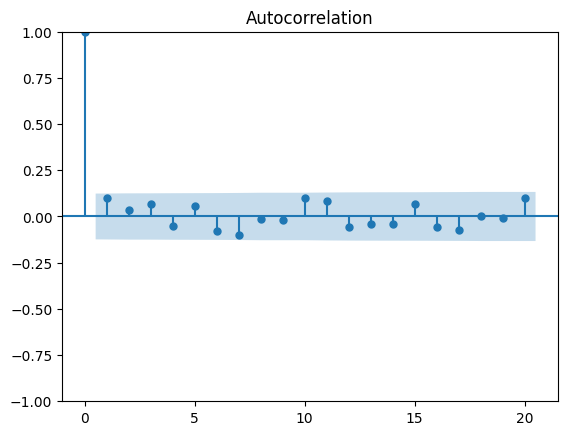

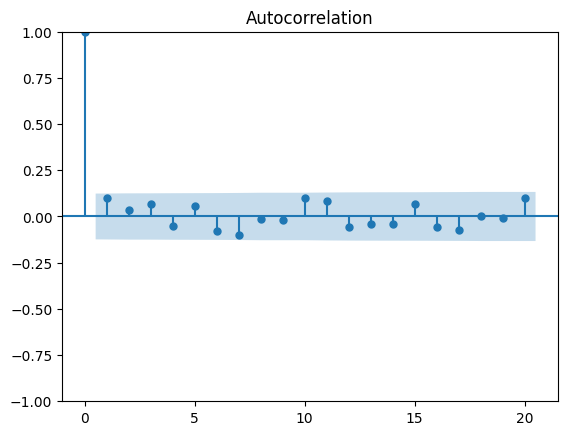

In [13]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(diff_close, lags=20)

Now that my data is stationary i can now forecast it.

In [45]:
len(df["Close"])

251

In [47]:
train = df[:200]
test = df[200:]
test

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-08-06 00:00:00-04:00,487.632000,500.617564,487.602057,498.920746,36441500,0.00,0.0
2026-08-07 00:00:00-04:00,498.271973,504.230757,497.792895,499.050507,28846200,0.00,0.0
2026-08-10 00:00:00-04:00,502.494059,512.764702,501.326244,505.109131,31206100,0.00,0.0
2026-08-11 00:00:00-04:00,503.382354,504.380475,498.611337,502.863342,23049800,0.00,0.0
2026-08-12 00:00:00-04:00,499.050523,500.557695,490.596436,491.504730,29001500,0.00,0.0
2026-08-13 00:00:00-04:00,492.343148,500.397992,492.083657,495.946381,23039000,0.00,0.0
2026-08-14 00:00:00-04:00,495.427334,499.070500,492.991947,494.469147,16217600,0.00,0.0
2026-08-17 00:00:00-04:00,489.219062,491.734316,477.511091,479.447449,29635800,0.00,0.0
2026-08-18 00:00:00-04:00,480.635209,483.360060,476.253443,480.725037,24087600,0.00,0.0


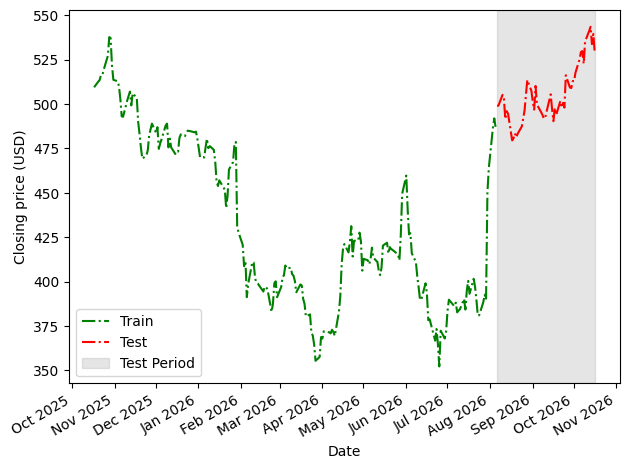

In [30]:
fig,ax = plt.subplots()
ax.plot(train.index, train["Close"], 'g-.', label="Train")
ax.plot(test.index, test["Close"], 'r-.', label="Test")
ax.set_xlabel("Date")
ax.set_ylabel("Closing price (USD)")

ax.axvspan(
    test.index[0],
    test.index[-1],
    color='#808080',
    alpha=0.2,
    label='Test Period'
)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc = 3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [58]:
mean = np.mean(train["Close"])
test.loc[:, 'pred_mean'] = mean  # predicting the historical mean for the next 51 steps
test.head()

C:\Users\Invate\AppData\Local\Temp\ipykernel_34112\445701529.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test.loc[:, 'pred_mean'] = mean  # predicting the historical mean for the next 51 steps


,Open,High,Low,Close,Volume,Dividends,Stock Splits,pred_drift,pred_mean
Date,,,,,,,,,
2026-08-06 00:00:00-04:00,487.632000,500.617564,487.602057,498.920746,36441500,0.0,0.0,15.666168,431.139342
2026-08-07 00:00:00-04:00,498.271973,504.230757,497.792895,499.050507,28846200,0.0,0.0,15.744499,431.139342
2026-08-10 00:00:00-04:00,502.494059,512.764702,501.326244,505.109131,31206100,0.0,0.0,15.822830,431.139342
2026-08-11 00:00:00-04:00,503.382354,504.380475,498.611337,502.863342,23049800,0.0,0.0,15.901161,431.139342
2026-08-12 00:00:00-04:00,499.050523,500.557695,490.596436,491.504730,29001500,0.0,0.0,15.979492,431.139342


In [61]:
#Another way to forecast is to predict the last known value.
last_value = train["Close"].iloc[-1]
test.loc[:, 'pred_last'] = last_value

test.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,pred_drift,pred_mean,pred_last
Date,,,,,,,,,,
2026-08-06 00:00:00-04:00,487.632000,500.617564,487.602057,498.920746,36441500,0.0,0.0,15.666168,431.139342,486.544067
2026-08-07 00:00:00-04:00,498.271973,504.230757,497.792895,499.050507,28846200,0.0,0.0,15.744499,431.139342,486.544067
2026-08-10 00:00:00-04:00,502.494059,512.764702,501.326244,505.109131,31206100,0.0,0.0,15.822830,431.139342,486.544067
2026-08-11 00:00:00-04:00,503.382354,504.380475,498.611337,502.863342,23049800,0.0,0.0,15.901161,431.139342,486.544067
2026-08-12 00:00:00-04:00,499.050523,500.557695,490.596436,491.504730,29001500,0.0,0.0,15.979492,431.139342,486.544067


In [62]:
# I will also apply the drift method which is a modification of predicting the last known value
deltaX = 251
deltaY = df["Close"].iloc[-1] - df["Close"].iloc[0]
drift = deltaY/deltaX
print(drift)

0.078330841672373


In [63]:
x_vals = np.arange(200, 251, 1)
pred_drift = drift * x_vals
test.loc[:, 'pred_drift'] = pred_drift
test.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,pred_drift,pred_mean,pred_last
Date,,,,,,,,,,
2026-08-06 00:00:00-04:00,487.632000,500.617564,487.602057,498.920746,36441500,0.0,0.0,15.666168,431.139342,486.544067
2026-08-07 00:00:00-04:00,498.271973,504.230757,497.792895,499.050507,28846200,0.0,0.0,15.744499,431.139342,486.544067
2026-08-10 00:00:00-04:00,502.494059,512.764702,501.326244,505.109131,31206100,0.0,0.0,15.822830,431.139342,486.544067
2026-08-11 00:00:00-04:00,503.382354,504.380475,498.611337,502.863342,23049800,0.0,0.0,15.901161,431.139342,486.544067
2026-08-12 00:00:00-04:00,499.050523,500.557695,490.596436,491.504730,29001500,0.0,0.0,15.979492,431.139342,486.544067


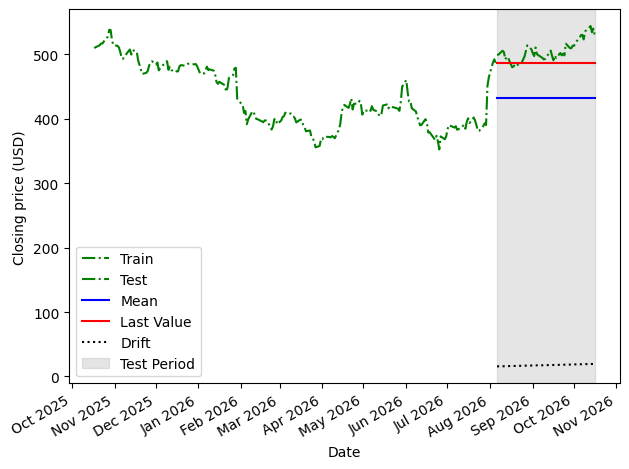

In [ ]:
fig,ax = plt.subplots()
ax.plot(train.index, train["Close"], 'g-.')
ax.plot(test.index, test["Close"], 'g-.')
ax.plot(test["pred_mean"], 'b-', label="Mean")
ax.plot(test["pred_last"], 'r-', label="Last Value")
ax.plot(test["pred_drift"], 'k:', label="Drift")
ax.set_xlabel("Date")
ax.set_ylabel("Closing price (USD)")

ax.axvspan(
    test.index[0],
    test.index[-1],
    color='#808080',
    alpha=0.2,
    label='Test Period'
)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc = 3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

The forecasts are rudimentary and so they fail to predict the sudden increase and decreases in the stock price. This makes sense as the stock is close to a random walk and the future change in a random walk is completely random and therefore unpredictable.

In [65]:
#Im going to use the MSE to measure the quality of the fit to the model
from sklearn.metrics import mean_squared_error
mse_mean = mean_squared_error(test["Close"],test["pred_mean"])
mse_last = mean_squared_error(test["Close"],test["pred_last"])
mse_drift = mean_squared_error(test["Close"],test["pred_drift"])
print(mse_mean, mse_last, mse_drift)

5760.354839009425 619.0798225097504 238009.7588271765


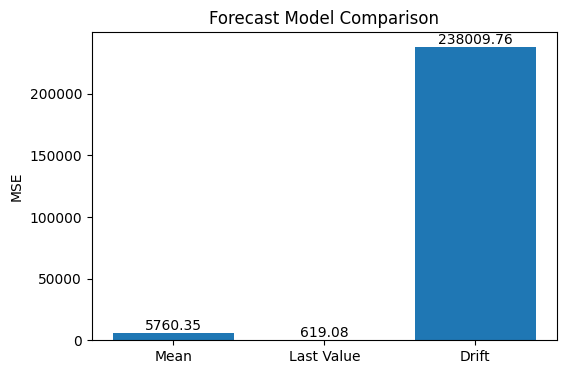

In [68]:
models = ["Mean", "Last Value", "Drift"]
mse_values = [mse_mean, mse_last, mse_drift]
plt.figure(figsize=(6, 4))
bars = plt.bar(models, mse_values)
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )
plt.ylabel("MSE")
plt.title("Forecast Model Comparison")
plt.show()

Therefore the best forecast was the last value out of the three forecasts.

One way to actually predict a random walk is forecasting the next timestep.

In [70]:
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2025-10-17 00:00:00-04:00,504.885987,511.273405,503.170094,509.388947,19867800,0.0,0.0
2025-10-20 00:00:00-04:00,510.410490,514.467140,509.240127,512.572693,14665600,0.0,0.0
2025-10-21 00:00:00-04:00,513.276940,514.457232,508.853314,513.435608,15586200,0.0,0.0
2025-10-22 00:00:00-04:00,516.897182,520.943844,513.485252,516.292114,18962700,0.0,0.0
2025-10-23 00:00:00-04:00,518.196409,519.674240,514.377791,516.311890,14023500,0.0,0.0


In [69]:
df_shift = df.shift(periods=1)
df_shift.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2025-10-17 00:00:00-04:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-10-20 00:00:00-04:00,504.885987,511.273405,503.170094,509.388947,19867800.0,0.0,0.0
2025-10-21 00:00:00-04:00,510.410490,514.467140,509.240127,512.572693,14665600.0,0.0,0.0
2025-10-22 00:00:00-04:00,513.276940,514.457232,508.853314,513.435608,15586200.0,0.0,0.0
2025-10-23 00:00:00-04:00,516.897182,520.943844,513.485252,516.292114,18962700.0,0.0,0.0


In [82]:
len(df_shift)

251

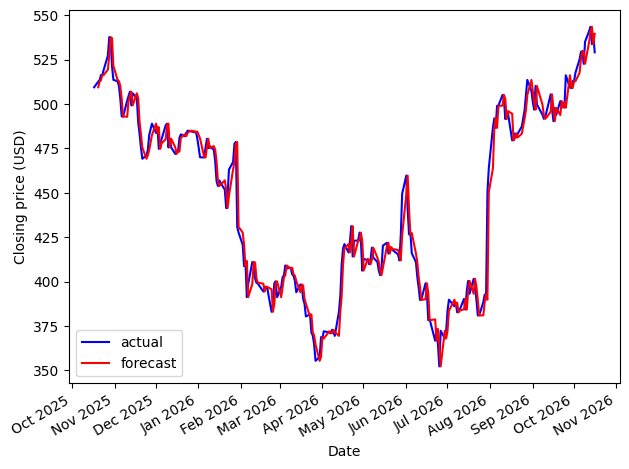

In [75]:
fig, ax = plt.subplots()
ax.plot(df['Close'], 'b-', label = "actual")
ax.plot(df_shift['Close'], 'r-', label = "forecast")
ax.legend(loc=3)
ax.set_xlabel("Date")
ax.set_ylabel("Closing price (USD)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
plt.tight_layout()

In [86]:
mse_one_step = mean_squared_error(
    test["Close"],
    df_shift.loc[test.index, "Close"]
)

print(mse_one_step)

50.490484005242
